# Makkah Retail Sales — 04: How Much Does Each Season Move Sales?

**Question:** By how much do Ramadan, Eid, Hajj and salary week change weekly card sales in Makkah?

**Method in one line:** compare each season week with the *normal* weeks around it.

Sales in Makkah grow over the years, so comparing a Ramadan week in 2025 with the average of all weeks since 2020 would exaggerate the effect. Instead, each week gets its own **baseline**: the median of the normal weeks within about 5 weeks on either side. The **uplift** is how far the week sits above or below that baseline, in %.

COVID curfew weeks are left out.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from dq.checks import _gregorian_events

CLEAN, INTERIM, OUT = Path("data/clean"), Path("data/interim"), Path("data/analysis")
OUT.mkdir(parents=True, exist_ok=True)

m = pd.read_csv(CLEAN / "makkah_weekly.csv", parse_dates=["starting_date"])
for col in ["covid_period", "excluded", "last_10_ramadan", "eid_fitr", "hajj", "eid_adha"]:
    m[col] = m[col].astype(str).eq("True")
m = m[~m.covid_period & ~m.excluded].set_index("starting_date").sort_index()
national = pd.read_csv(INTERIM / "national_weekly.csv", parse_dates=["starting_date"]).set_index("starting_date")["sales_m_sar"]
print(f"{len(m)} weeks of Makkah data, {m.index.min():%b %Y} – {m.index.max():%b %Y}")

287 weeks of Makkah data, Jun 2020 – Nov 2026


## 1. Label each week with its season

When a week belongs to more than one season, the stronger event wins, in this order:
Hajj & Eid al-Adha → Eid al-Fitr → last 10 days of Ramadan → rest of Ramadan → salary week → normal.

In [2]:
m["salary_week"] = [("salary week" in _gregorian_events(d)) for d in m.index]

def season(r):
    if r.hajj or r.eid_adha: return "Hajj & Eid al-Adha"
    if r.eid_fitr:           return "Eid al-Fitr"
    if r.last_10_ramadan:    return "Ramadan: last 10 days"
    if r.ramadan_days > 0:   return "Ramadan: first 20 days"
    if r.salary_week:        return "Salary week"
    return "Normal week"

m["season"] = m.apply(season, axis=1)
m.season.value_counts()

season
Normal week               191
Salary week                55
Ramadan: first 20 days     17
Hajj & Eid al-Adha         10
Ramadan: last 10 days       8
Eid al-Fitr                 6
Name: count, dtype: int64

## 2. Baseline and uplift

In [3]:
normal = m.sales_m_sar.where(m.season == "Normal week")
m["baseline"] = normal.rolling("70D", center=True, min_periods=3).median()
m["uplift_pct"] = (m.sales_m_sar / m.baseline - 1) * 100

ORDER = ["Ramadan: last 10 days", "Ramadan: first 20 days", "Eid al-Fitr",
         "Hajj & Eid al-Adha", "Salary week", "Normal week"]
summary = (m.groupby("season").uplift_pct
           .agg(median="median", lowest="min", highest="max", weeks="count")
           .reindex(ORDER).round(0))
summary.to_csv(OUT / "season_uplift.csv")
summary

,median,lowest,highest,weeks
season,,,,
Ramadan: last 10 days,100.0,50.0,191.0,8
Ramadan: first 20 days,39.0,-13.0,72.0,14
Eid al-Fitr,30.0,-0.0,76.0,6
Hajj & Eid al-Adha,17.0,-33.0,32.0,10
Salary week,15.0,-16.0,43.0,55
Normal week,0.0,-27.0,62.0,190


**How to read it:** `median` is the typical effect. `lowest` and `highest` show how much it varies between years.
Normal weeks sit at ~0% by construction — that is the check that the baseline works.

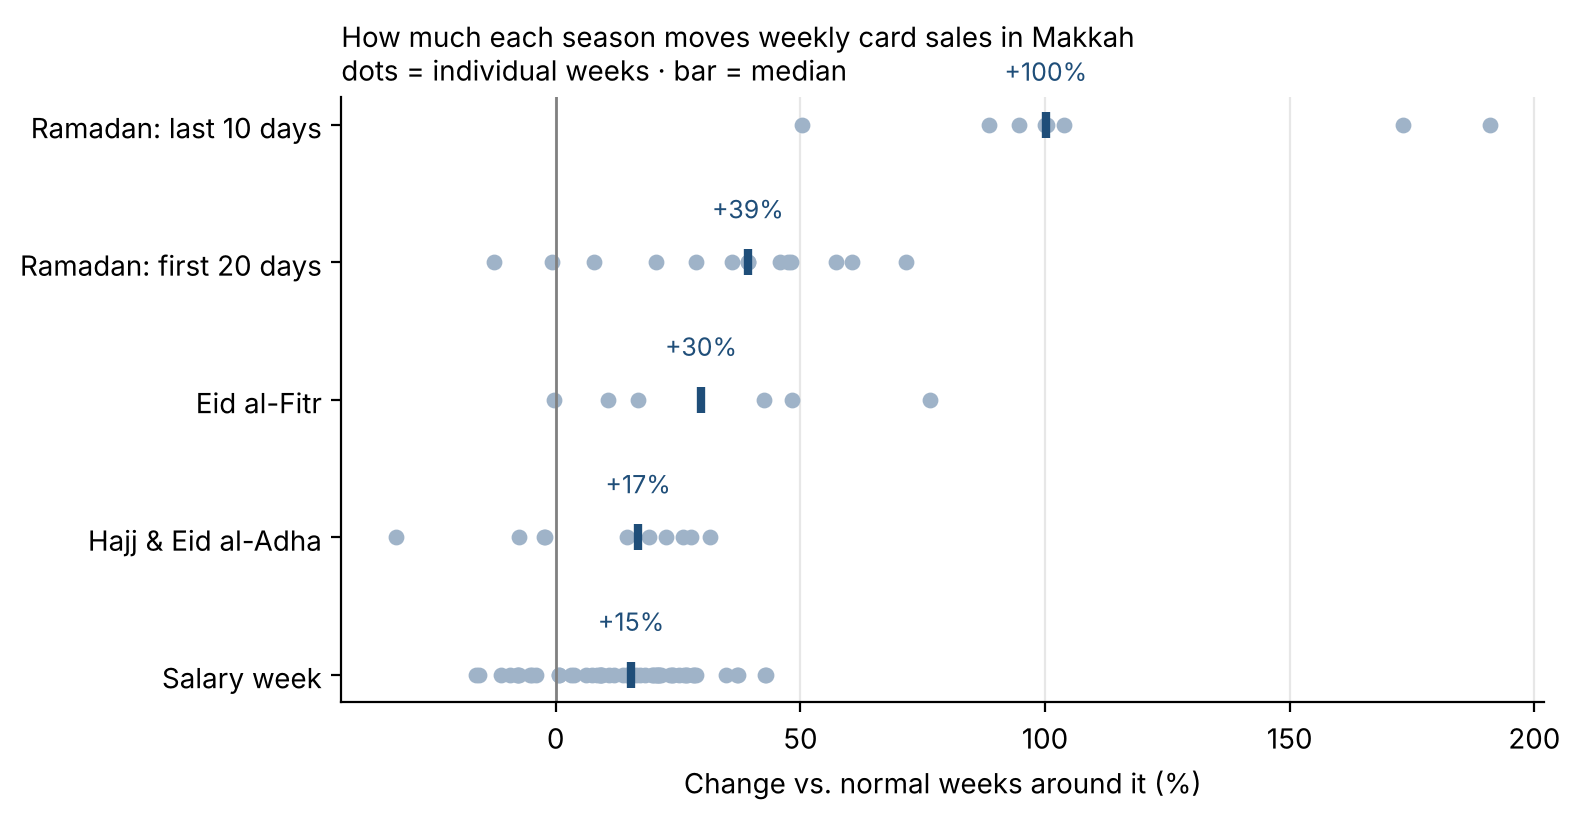

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.2))
seasons = ORDER[:-1]
for i, s in enumerate(seasons):
    vals = m.loc[m.season == s, "uplift_pct"].dropna()
    ax.scatter(vals, [i] * len(vals), color="#9fb3c8", s=22, zorder=2)
    ax.scatter(vals.median(), i, color="#1f4e79", s=90, marker="|", linewidths=3, zorder=3)
    ax.text(vals.median(), i - 0.32, f"{vals.median():+.0f}%", ha="center", fontsize=9, color="#1f4e79")
ax.axvline(0, color="gray", lw=1)
ax.set_yticks(range(len(seasons)), seasons); ax.invert_yaxis()
ax.set_xlabel("Change vs. normal weeks around it (%)")
ax.set_title("How much each season moves weekly card sales in Makkah\ndots = individual weeks · bar = median", loc="left", fontsize=10)
ax.grid(axis="x", alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(OUT / "season_uplift.png", dpi=160); plt.show()

## 3. Is the Ramadan peak growing?

The median weekly sales in the last 10 days of Ramadan, by Hijri year, next to the normal-week median of the same year.

In [5]:
yearly = (m.groupby(["hijri_year", "season"]).sales_m_sar.median().unstack()
          [["Normal week", "Ramadan: last 10 days"]].dropna())
yearly = yearly.round(0)
yearly["peak_vs_normal"] = (yearly["Ramadan: last 10 days"] / yearly["Normal week"]).round(2)
yearly

season,Normal week,Ramadan: last 10 days,peak_vs_normal
hijri_year,,,
1442,249.0,534.0,2.14
1443,315.0,788.0,2.50
1444,414.0,807.0,1.95
1445,475.0,913.0,1.92
1446,495.0,1076.0,2.17


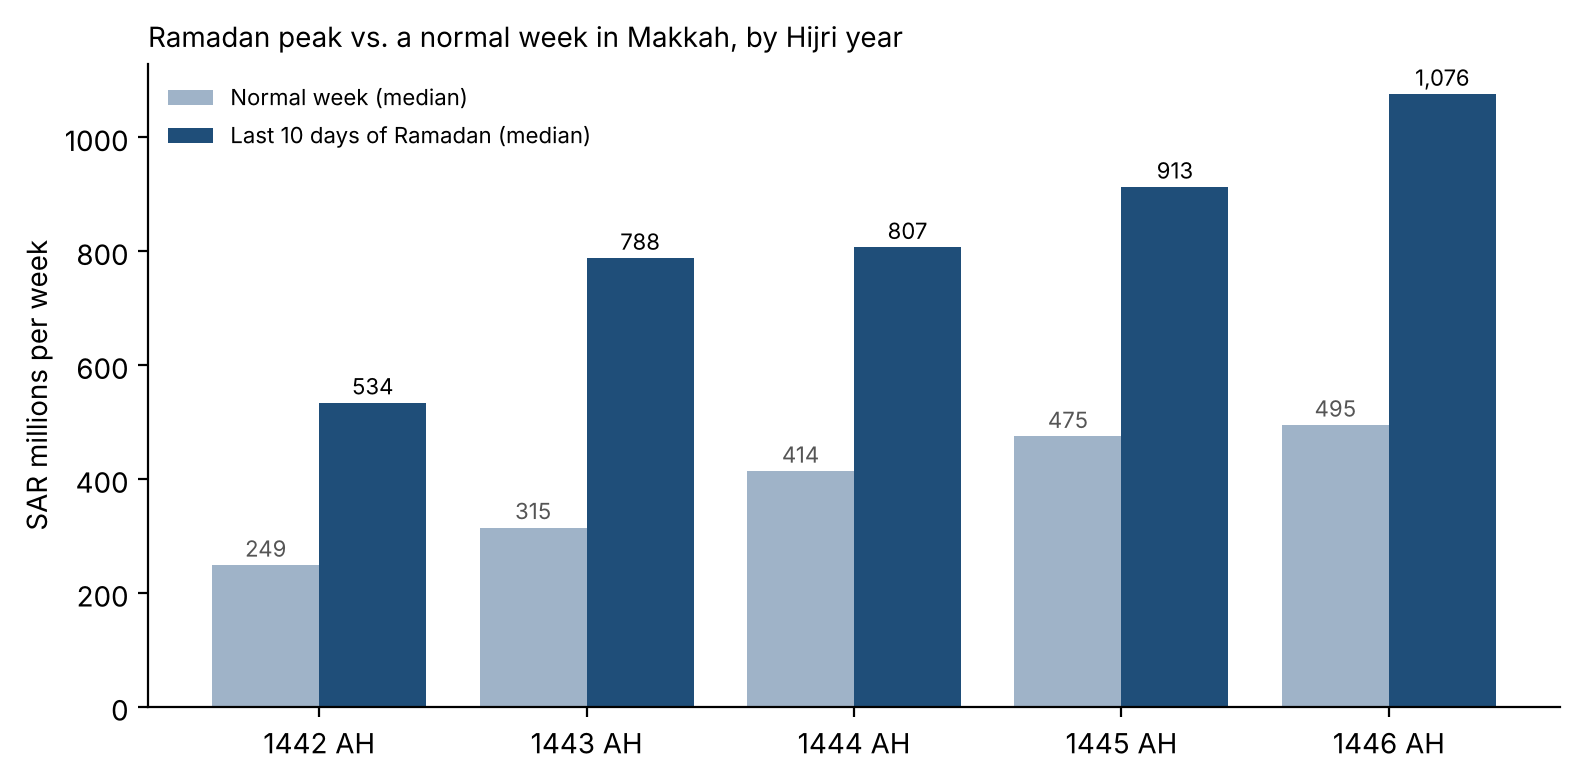

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
x = range(len(yearly))
ax.bar([i - 0.2 for i in x], yearly["Normal week"], width=0.4, color="#9fb3c8", label="Normal week (median)")
ax.bar([i + 0.2 for i in x], yearly["Ramadan: last 10 days"], width=0.4, color="#1f4e79", label="Last 10 days of Ramadan (median)")
for i, (n, p) in enumerate(zip(yearly["Normal week"], yearly["Ramadan: last 10 days"])):
    ax.text(i + 0.2, p + 15, f"{p:,.0f}", ha="center", fontsize=8)
    ax.text(i - 0.2, n + 15, f"{n:,.0f}", ha="center", fontsize=8, color="#555")
ax.set_xticks(list(x), [f"{int(y)} AH" for y in yearly.index])
ax.set_ylabel("SAR millions per week"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Ramadan peak vs. a normal week in Makkah, by Hijri year", loc="left", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(OUT / "ramadan_by_year.png", dpi=160); plt.show()

## 4. Makkah's share of national sales

Uplift in riyals shows how Makkah changes against itself. Its **share of all card sales in the Kingdom** shows how it changes against the rest of the country — useful when both move at the same time (for example, salary week lifts every city). Available for the CSV period (to Jul 2025).

In [7]:
m["share_pct"] = (m.sales_m_sar / national * 100)
share = m.dropna(subset=["share_pct"]).groupby("season").share_pct.median().reindex(ORDER).round(2)
share.to_frame("Makkah share of national sales (%)")

,Makkah share of national sales (%)
season,
Ramadan: last 10 days,6.08
Ramadan: first 20 days,5.55
Eid al-Fitr,4.75
Hajj & Eid al-Adha,3.74
Salary week,3.61
Normal week,3.70


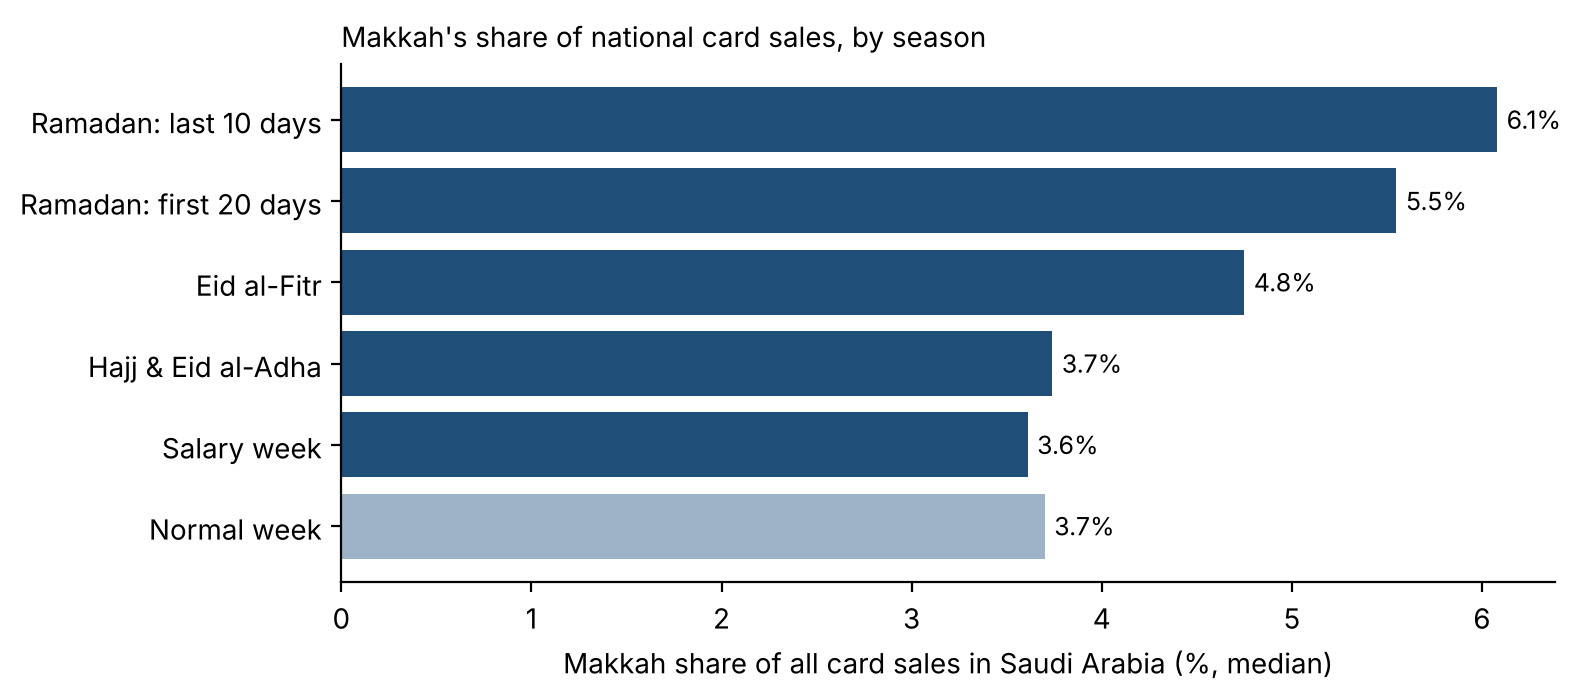

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.6))
vals = share.dropna()
colors = ["#9fb3c8" if s == "Normal week" else "#1f4e79" for s in vals.index]
ax.barh(vals.index, vals.values, color=colors)
for i, v in enumerate(vals.values):
    ax.text(v + 0.05, i, f"{v:.1f}%", va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlabel("Makkah share of all card sales in Saudi Arabia (%, median)")
ax.set_title("Makkah's share of national card sales, by season", loc="left", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(OUT / "makkah_share_by_season.png", dpi=160); plt.show()

## 5. Findings

In [9]:
u = summary["median"]
print(f"• Last 10 days of Ramadan: {u['Ramadan: last 10 days']:+.0f}% vs normal weeks — the biggest effect.")
print(f"• First 20 days of Ramadan: {u['Ramadan: first 20 days']:+.0f}%;  Eid al-Fitr week: {u['Eid al-Fitr']:+.0f}%.")
print(f"• Hajj & Eid al-Adha: {u['Hajj & Eid al-Adha']:+.0f}% (range {summary.loc['Hajj & Eid al-Adha','lowest']:+.0f}% "
      f"to {summary.loc['Hajj & Eid al-Adha','highest']:+.0f}%) — far smaller than Ramadan.")
print(f"• Salary week: {u['Salary week']:+.0f}%.")
print(f"• Makkah's share of national sales: {share['Normal week']:.1f}% in a normal week, "
      f"{share['Hajj & Eid al-Adha']:.1f}% in Hajj weeks, {share['Ramadan: last 10 days']:.1f}% in the last 10 days of Ramadan.")

• Last 10 days of Ramadan: +100% vs normal weeks — the biggest effect.
• First 20 days of Ramadan: +39%;  Eid al-Fitr week: +30%.
• Hajj & Eid al-Adha: +17% (range -33% to +32%) — far smaller than Ramadan.
• Salary week: +15%.
• Makkah's share of national sales: 3.7% in a normal week, 3.7% in Hajj weeks, 6.1% in the last 10 days of Ramadan.


## Limits

- The baseline is the median of nearby normal weeks; where many season weeks sit close together (Ramadan into Eid), fewer normal weeks are available and the baseline is less precise.
- Hajj 1442 (2021) ran with very limited pilgrims, which pulls the lowest Hajj value down.
- Card sales are not all spending: cash and pre-paid packages (common for pilgrims) are not in this data, so the Hajj effect on total spending may be larger than shown here.

**Next:** `05_forecast.ipynb` — forecast the next Ramadan season and test the forecast on weeks the model has not seen.